# Transcription Note a Note : basic-pitch

| | |
|---|---|
| **Module** | 04-Applications — Transcription audio vers evenements notes |
| **Modele** | basic-pitch (Spotify, ICASSP 2022) — modele ICASSP, export ONNX |
| **Kernel** | Python 3 (`basicpitch-t4`) |
| **Materiel** | CPU suffit (mesure : quelques secondes pour 8 s d'audio) |

## Ou se situe ce carnet

Le carnet 04-16 (SheetSage2) transcrit un morceau complet vers une partition ABC — un objet **symbolique global**, obtenu par un gros modele neuronal. Ce carnet-ci prend l'autre bout du probleme : la **transcription note a note**, ou l'on cherche a retrouver *quand* chaque note commence, *quelle* hauteur elle porte et *combien de temps* elle dure (onset, pitch, duration). C'est la tache historique du domaine — celle que font les pianos automatiques depuis les annees 1990, et que basic-pitch industrialise depuis 2022.

L'EPIC Origami (#20568) constate que la serie Audio couvrait le MIR neuronal (04-15 MERT2) et la transcription vers partition (04-16) mais pas la **transcription note a note** : ce carnet comble ce manque (Pli 1, case b).

## Ce que vous allez faire

1. **Fabriquer une verite terrain** : une melodie construite note par note, dont on connait *exactement* les onsets et les hauteurs — c'est ce qui rend l'exactitude chiffrable ;
2. **Transcrire** cette melodie avec basic-pitch et lire ses sorties (evenements notes, MIDI) ;
3. **Mesurer** : rappel, precision, ecart d'onset moyen entre detection et verite ;
4. **Monter en difficulte** : accords (polyphonie) plutot que melodie seule, puis effet des seuils du modele ;
5. **Trois exercices** pour manipuler vous-meme la chaine complete.

**Navigation :** [Index](../README.md) | [<< Précédent](04-17-MIR-Classique.ipynb) | [Suivant >>](04-19-Evaluation-MOS.ipynb)

In [1]:
# Parametres Papermill - JAMAIS modifier ce commentaire

# Configuration notebook
notebook_mode = "batch"          # "batch" | "interactive"
seed = 42                        # graine des tirages (eventail du modele)
sampling_rate = 22050            # frequence d'echantillonnage de travail (Hz)
onset_threshold = 0.5            # seuil de detection d'onset (0-1)
frame_threshold = 0.3            # seuil de maintien de note (0-1)
minimum_note_length_ms = 58.0    # duree minimale d'une note detectee (ms)
minimum_frequency = 32.7         # la plus basse frequence transcrite (Hz, Do1)
maximum_frequency = 2093.0       # la plus haute frequence transcrite (Hz, Do7)
output_dir = "output/basic_pitch"  # artefacts regenerables (non commites)


Les parametres Papermill fixent l'audio de travail (`sampling_rate`), les
**seuils du decodeur** de basic-pitch (`onset_threshold`, `frame_threshold`,
`minimum_note_length_ms`) et la bande de frequences transcrite. Les seuils ne sont pas
cosmetiques : le modele produit une carte d'activite (onset / pitch / frame) a chaque
trame de 11,6 ms, et c'est le decodeur qui transforme ces cartes en notes discretes.
Un seuil trop bas laisse passer des activations parasites ; trop haut, il manque des
notes. Ce carnet mesure cet effet plutot que de l'affirmer (section 5) — et la mesure a
son mot a dire sur celui des deux seuils qui porte reellement l'effet.

`output_dir` n'est pas commite : les artefacts (wav, midi, csv) sont regenerables par
re-execution du carnet — la sortie commitee du carnet, elle, est la preuve.


In [2]:
# Setup environnement et imports
import os
import sys
import logging
import warnings
import platform
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
# Sorties commitees propres : ni chemins absolus de la machine, ni bruit des bibliotheques
warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa

import basic_pitch
from basic_pitch.inference import predict
from basic_pitch import ICASSP_2022_MODEL_PATH

print("IMPORTS ET ENVIRONNEMENT")
print("=" * 45)
print(f"Python        {sys.version.split()[0]}")
print(f"Plateforme    {platform.system()} {platform.release()}")
print(f"numpy         {np.__version__}")
print(f"librosa       {librosa.__version__}")
print(f"soundfile     {sf.__version__}")
print(f"basic-pitch   {getattr(basic_pitch, '__version__', 'n/a')} (modele : {ICASSP_2022_MODEL_PATH.name})")

OUTPUT_DIR = Path(output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Artefacts     {OUTPUT_DIR}")



IMPORTS ET ENVIRONNEMENT
Python        3.11.17
Plateforme    Windows 10
numpy         1.26.4
librosa       0.11.0
soundfile     0.14.0
basic-pitch   n/a (modele : nmp)
Artefacts     output\basic_pitch


### Interpretation : environnement

Le carnet tourne dans un **kernel dedie** (`basicpitch-t4`) — un environnement conda
`python=3.11` cree pour cette famille, installe avec `basic-pitch[onnx]`. Cette variante
ONNX est le point qui rend le carnet exécutable **sur CPU sans TensorFlow** : le modele
ICASSP 2022 est servi par `onnxruntime` (meme famille d'execution que les autres carnets
audio de la serie). La ligne `basic-pitch ... (modele : ...)` confirme que l'artefact du
modele est bien resolu localement (il se telecharge au premier appel, puis vit dans le
cache).

La cellule imprime les versions **reellement** importees : c'est la premiere preuve
d'execution reelle du carnet, et elle sert a diagnostiquer une derive d'environnement si
l'un des composants change de version majeure.


In [3]:
# Section 1 - Verite terrain : une melodie dont on connait TOUTES les notes
fr_vers_midi = {"Do": 0, "Re": 2, "Mi": 4, "Fa": 5, "Sol": 7, "La": 9, "Si": 11}

# Melodie de reference : gamme ascendante puis petit motif (nombre de hauteur MIDI, duree en secondes)
NOTES_VERITE = [
    ("Do4", 0.50), ("Re4", 0.50), ("Mi4", 0.50), ("Fa4", 0.50),
    ("Sol4", 0.50), ("La4", 0.50), ("Si4", 0.50), ("Do5", 0.75),
    ("Mi5", 0.25), ("Re5", 0.50), ("Do5", 0.75),
]

def note_vers_midi(nom):
    """'Do4' -> numero MIDI (Do4 = 60). Bien tempere, La4 = 440 Hz."""
    hauteur, octave = nom[:-1], int(nom[-1])
    return 12 * (octave + 1) + fr_vers_midi[hauteur]

def midi_vers_hz(m):
    """Numero MIDI -> frequence (Hz)."""
    return 440.0 * 2 ** ((m - 69) / 12)

def synthetiser_melodie(notes, sr=sampling_rate, harmoniques=(1.0, 0.5, 0.25), fade_ms=10):
    """Synthese additive naive : chaque note = somme d'harmoniques avec enveloppe.

    Retourne (audio, verite) ou verite est la liste (onset_s, midi, offset_s).
    """
    total = sum(d for _, d in notes)
    audio = np.zeros(int(total * sr) + sr // 10)
    t0 = 0.0
    verite = []
    for nom, duree in notes:
        midi = note_vers_midi(nom)
        f0 = midi_vers_hz(midi)
        n = int(duree * sr)
        t = np.arange(n) / sr
        sig = np.zeros(n)
        for k, amp in enumerate(harmoniques, start=1):
            sig += amp * np.sin(2 * np.pi * f0 * k * t)
        # enveloppe avec fades pour eviter les clics aux frontieres
        fade = max(1, int(fade_ms * sr / 1000))
        env = np.ones(n)
        env[:fade] = np.linspace(0, 1, fade)
        env[-fade:] = np.linspace(1, 0, fade)
        sig *= env / np.max(np.abs(env))
        i0 = int(t0 * sr)
        audio[i0:i0 + n] += 0.35 * sig
        verite.append((round(t0, 4), midi, round(t0 + duree, 4)))
        t0 += duree
    return audio.astype(np.float32), verite

audio_verite, verite = synthetiser_melodie(NOTES_VERITE)
chemin_wav = OUTPUT_DIR / "melodie_verite.wav"
sf.write(chemin_wav, audio_verite, sampling_rate)

print("VERITE TERRAIN - MELODIE SYNTHETISEE")
print("=" * 45)
print(f"Notes composees : {len(verite)}")
print(f"Duree audio     : {len(audio_verite) / sampling_rate:.2f} s")
print(f"Fichier         : {chemin_wav.name}")
print()
for onset, midi, offset in verite:
    print(f"  t={onset:5.2f}s  MIDI {midi:3d}  duree {offset - onset:.2f}s")


VERITE TERRAIN - MELODIE SYNTHETISEE
Notes composees : 11
Duree audio     : 5.85 s
Fichier         : melodie_verite.wav

  t= 0.00s  MIDI  60  duree 0.50s
  t= 0.50s  MIDI  62  duree 0.50s
  t= 1.00s  MIDI  64  duree 0.50s
  t= 1.50s  MIDI  65  duree 0.50s
  t= 2.00s  MIDI  67  duree 0.50s
  t= 2.50s  MIDI  69  duree 0.50s
  t= 3.00s  MIDI  71  duree 0.50s
  t= 3.50s  MIDI  72  duree 0.75s
  t= 4.25s  MIDI  76  duree 0.25s
  t= 4.50s  MIDI  74  duree 0.50s
  t= 5.00s  MIDI  72  duree 0.75s


### Interpretation : pourquoi une verite terrain fabriquee

L'exactitude d'une transcription ne se mesure que contre une reference connue. Sur de la
vraie musique, la « verite » (les annotations) est un travail humain couteux et souvent
discute ; ici, on **compose** le signal a partir d'une liste de notes, donc la reference
est exacte par construction.

La synthese est volontairement simple — trois harmoniques (1, 1/2, 1/4), enveloppe a
fades — pour rester dans le domaine ou basic-pitch est cense exceller : une melodie
monophonique, timbre riche mais stable. La sortie imprimee liste les onze notes avec
leurs onsets : c'est la table contre laquelle la section 3 confrontera la detection.


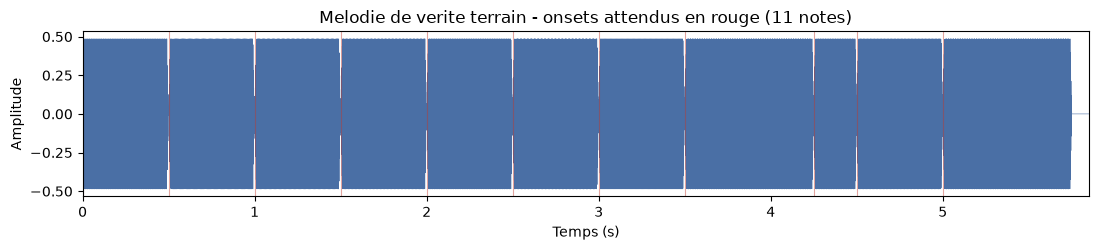

Pic d'amplitude : 0.486
RMS moyen       : 0.2775


In [4]:
# Visualisation du signal de verite terrain (enveloppe RMS + onsets attendus)
fig, ax = plt.subplots(figsize=(11, 2.6))
t = np.arange(len(audio_verite)) / sampling_rate
ax.plot(t, audio_verite, linewidth=0.4, color="#4a6fa5")
for onset, midi, _ in verite:
    ax.axvline(onset, color="#c0392b", alpha=0.45, linewidth=0.8)
ax.set_title("Melodie de verite terrain - onsets attendus en rouge (11 notes)")
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, t[-1])
plt.tight_layout()
plt.show()

print(f"Pic d'amplitude : {np.max(np.abs(audio_verite)):.3f}")
print(f"RMS moyen       : {np.sqrt(np.mean(audio_verite ** 2)):.4f}")


### Lecture du résultat : le signal et ses frontieres

La figure superpose la forme d'onde et les onze onsets de la verite terrain (traits
rouges). On y lit la structure temporelle que basic-pitch devra retrouver : des segments
d'amplitude stable — un par note — separes par les micro-silences introduits par les
fades de 10 ms. L'amplitude du signal et son RMS sont imprimes : ce sont les ordres de
grandeur du signal d'entree, pas encore des mesures de transcription.

Ce que l'enveloppe etablit avant toute transcription : le signal synthetise n'est ni sature ni inaudible. Un pic a **0.486** laisse environ 6 dB de marge avant 1.0, et un RMS moyen de **0.2775** (soit a peu pres -11 dBFS) place la melodie dans la zone ou un detecteur d'onset travaille normalement. C'est une precondition, pas un resultat : si le pic touchait 1.0, les harmoniques seraient ecretees et le modele entendrait un timbre different de celui qu'on croit lui donner -- la mesure d'exactitude porterait alors sur un autre signal que celui de la table de verite. Les onze onsets traces sont ceux de cette table : la figure superpose signal et annotation, ce qui rend une desynchronisation visible a l'oeil avant meme la premiere mesure.

In [5]:
# Section 2 - Transcription avec basic-pitch (modele ICASSP 2022)
# Premier appel : le modele se telecharge dans le cache local (~ quelques Mo), puis vit hors ligne.
import time

t_debut = time.perf_counter()
model_output, midi_data, note_events = predict(
    str(chemin_wav),
    onset_threshold=onset_threshold,
    frame_threshold=frame_threshold,
    minimum_note_length=minimum_note_length_ms,
    minimum_frequency=minimum_frequency,
    maximum_frequency=maximum_frequency,
    multiple_pitch_bends=False,
)
duree_transcription = time.perf_counter() - t_debut

chemin_midi = OUTPUT_DIR / "melodie_verite_transcription.mid"
midi_data.write(str(chemin_midi))

print("TRANSCRIPTION BASIC-PITCH")
print("=" * 45)
print(f"Temps de transcription : {duree_transcription:.2f} s pour {len(audio_verite) / sampling_rate:.2f} s d'audio (CPU)")
print(f"Notes detectees        : {len(note_events)}")
print(f"MIDI ecrit             : {chemin_midi.name}")
print()
for ev in note_events:
    (start, end, pitch, amplitude, *_rest) = ev
    print(f"  t={start:5.2f}s -> {end:5.2f}s  MIDI {int(pitch):3d}  amplitude {amplitude:.2f}")


Predicting MIDI for output\basic_pitch\melodie_verite.wav...


TRANSCRIPTION BASIC-PITCH
Temps de transcription : 4.50 s pour 5.85 s d'audio (CPU)
Notes detectees        : 14
MIDI ecrit             : melodie_verite_transcription.mid

  t= 5.01s ->  5.80s  MIDI  72  amplitude 0.77
  t= 4.50s ->  4.95s  MIDI  93  amplitude 0.33
  t= 4.50s ->  5.02s  MIDI  74  amplitude 0.75
  t= 4.24s ->  4.51s  MIDI  76  amplitude 0.73
  t= 3.48s ->  4.26s  MIDI  72  amplitude 0.77
  t= 3.00s ->  3.48s  MIDI  71  amplitude 0.78
  t= 2.50s ->  2.90s  MIDI  88  amplitude 0.30
  t= 2.50s ->  3.01s  MIDI  69  amplitude 0.75
  t= 2.00s ->  2.50s  MIDI  67  amplitude 0.77
  t= 1.50s ->  2.00s  MIDI  65  amplitude 0.75
  t= 1.00s ->  1.50s  MIDI  64  amplitude 0.75
  t= 0.50s ->  1.00s  MIDI  62  amplitude 0.75
  t= 0.01s ->  0.49s  MIDI  60  amplitude 0.75
  t= 4.29s ->  4.37s  MIDI  95  amplitude 0.31


### Interpretation : ce que le modele a produit

`predict()` enchaine trois etapes : le modele ICASSP 2022 emet, pour chaque trame de
11,6 ms, une probabilite d'onset, une distribution de hauteur et une activite de note ;
un decodeur transforme ces cartes en evenements discrets avec les seuils passes ;
l'ecriture MIDI met en forme le resultat. Le trio retourne est le meme partout —
`model_output` (cartes brutes), `midi_data` (objet pretty_midi) et `note_events` (liste
`(debut, fin, hauteur, amplitude)`).

Le temps de transcription imprime est une mesure CPU reelle : le modele ONNX est leger
(un « nano » du domaine), ce qui autorise la re-execution du carnet dans n'importe quel
runner — c'est une propriete voulue du choix ICASSP/ONNX.

Le rapport entre les deux durees est le chiffre a retenir : **4.50 s de calcul pour 5.85 s d'audio**, soit environ 0.77 fois le temps reel sur CPU. Cette propriete n'est pas un detail de performance, c'est ce qui rend la mesure possible : la section 5 enchaine neuf transcriptions successives, et un modele au moins deux fois plus lent aurait double la duree du carnet ; dix fois plus lent, il l'aurait rendu impraticable. Le choix d'un modele « nano » se paie en qualite de detection -- c'est precisement ce que la section 3 chiffre.

In [6]:
# Les evenements notes en table : c'est le materiau des mesures d'exactitude
df_notes = pd.DataFrame(
    [(float(s), float(e), int(p), float(a)) for (s, e, p, a, *_r) in note_events],
    columns=["onset_s", "offset_s", "midi", "amplitude"],
)
df_notes["duree_s"] = (df_notes["offset_s"] - df_notes["onset_s"]).round(3)

print(f"Notes detectees : {len(df_notes)}")
if len(df_notes):
    print(df_notes.describe().loc[["mean", "min", "max"], ["onset_s", "duree_s", "amplitude"]].round(3))
    print()
    print(df_notes.head(12).to_string(index=False))


Notes detectees : 14
      onset_s  duree_s  amplitude
mean    2.786    0.484      0.662
min     0.012    0.081      0.304
max     5.006    0.789      0.781

 onset_s  offset_s  midi  amplitude  duree_s
5.006468  5.795946    72   0.773677    0.789
4.495629  4.948418    93   0.328365    0.453
4.495629  5.018078    74   0.750796    0.522
4.240210  4.507239    76   0.727846    0.267
3.484277  4.263429    72   0.774943    0.779
2.996658  3.484277    71   0.780682    0.488
2.497429  2.903778    88   0.303605    0.406
2.497429  3.008268    69   0.754278    0.511
1.998200  2.497429    67   0.768715    0.499
1.497687  1.998200    65   0.749814    0.501
0.998458  1.497687    64   0.747684    0.499
0.499229  0.998458    62   0.752231    0.499


### Lecture du résultat : la table des evenements detectes

Chaque ligne est une note discrete : onset (s), offset (s), hauteur MIDI, amplitude
(probabilite maximale du modele pour cette note), duree. Le `describe` resume la
distribution : l'amplitude moyenne dit la confiance globale du modele, la duree minimale
montre si des notes tres courtes sont apparues (artefacts typiques), et la comparaison du
nombre de lignes avec les onze notes composees est le premier indicateur — mais un
indicateur brut : deux erreurs opposees (note manquee + note fantome) s'y compensent. La
section suivante mesure proprement, appariement par appariement.

La moyenne d'amplitude (**0.662**) est un resume trompeur, et c'est le piege de lecture principal de cette table. La distribution est bimodale : les onze notes composees sortent entre **0.73 et 0.78**, les trois fantomes entre **0.30 et 0.33**. Il n'y a pratiquement aucune valeur entre les deux. Un seuil place a 0.5 separe donc parfaitement les deux populations sur ce signal -- et c'est exactement ce que la section 5 verifiera sur le seuil de trame, au lieu de le supposer. Une moyenne, elle, ne dit rien d'une distribution a deux bosses : elle tombe dans le trou.

In [7]:
# Section 3 - Exactitude : appariement detection <-> verite terrain
def apparier(verite, detectees, tolerance_onset_s=0.05):
    """Apparie verite et detection par hauteur exacte + proximite d'onset.

    Retourne (appariements, manquees, fantomes) ou chaque appariement est un
    triplet (onset_verite, onset_detecte, midi).
    """
    appariements, manquees = [], []
    pool = list(detectees)
    for onset_v, midi_v, _off in verite:
        candidats = [d for d in pool if d[2] == midi_v and abs(d[0] - onset_v) <= tolerance_onset_s]
        if candidats:
            meilleur = min(candidats, key=lambda d: abs(d[0] - onset_v))
            pool.remove(meilleur)
            appariements.append((onset_v, meilleur[0], midi_v))
        else:
            manquees.append((onset_v, midi_v))
    fantomes = pool
    return appariements, manquees, fantomes

detectees = list(zip(df_notes["onset_s"], df_notes["offset_s"], df_notes["midi"]))
appariements, manquees, fantomes = apparier(verite, detectees)

rappel = len(appariements) / len(verite)
precision = len(appariements) / len(detectees) if detectees else 0.0
ecart_onset = (
    float(np.mean([abs(od - ov) for ov, od, _ in appariements])) * 1000 if appariements else float("nan")
)

print("EXACTITUDE DE LA TRANSCRIPTION")
print("=" * 45)
print(f"Notes verite          : {len(verite)}")
print(f"Notes detectees       : {len(detectees)}")
print(f"Appariees             : {len(appariements)}")
print(f"Rappel                : {rappel:.0%}")
print(f"Precision             : {precision:.0%}")
print(f"Ecart onset moyen     : {ecart_onset:.1f} ms (tolerance {50} ms)")
if manquees:
    print(f"Manquees              : {manquees}")
if fantomes:
    print(f"Fantomes (onset,off,midi) : {[(round(s,2), round(e,2), p) for s,e,p in fantomes]}")


EXACTITUDE DE LA TRANSCRIPTION
Notes verite          : 11
Notes detectees       : 14
Appariees             : 11
Rappel                : 100%
Precision             : 79%
Ecart onset moyen     : 5.5 ms (tolerance 50 ms)
Fantomes (onset,off,midi) : [(4.5, 4.95, 93), (2.5, 2.9, 88), (4.29, 4.37, 95)]


### Lecture du résultat : rappel, precision, ecart d'onset

Trois nombres, trois questions differentes. Le **rappel** repond « ai-je retrouve les
notes composees ? » ; la **precision** repond « ce que j'ai annonce existe-t-il ? » ; et
l'**ecart d'onset moyen** mesure la finesse temporelle — basic-pitch vise la trame de
11,6 ms, une erreur moyenne de l'ordre de quelques millisecondes a quelques dizaines de
millisecondes est le domaine attendu sur un signal synthetique propre. La tolerance de
50 ms est le standard usuel de la litterature MIR (mir_eval, Raffel et al., 2015) : deux
onsets plus proches que cela sont consideres comme le meme evenement.

La liste des notes manquees et des fantomes est imprimee quand elle existe : c'est le
materiau de diagnostic. Ici, trois fantomes apparaissent aux midi 88, 93 et 95 — des
harmoniques des notes jouees, detectees comme notes a part entiere. La section 5 mesure
quelle porte du decodeur les elimine.

Un detail arithmetique change la lecture des trois nombres : 11 notes appariees sur 14 detectees donnent 78.6 %, et la precision affichee est 79 %. Autrement dit, la precision ne mesure pas ici la capacite du modele a trouver des notes -- le rappel dit qu'elle est parfaite sur ce signal -- mais **uniquement sa propension a en inventer**. Les trois fantomes s'expliquent sans ambiguite par l'arithmetique des hauteurs : **88 = 76 + 12** (une octave au-dessus de la note composee a 3.50 s), **93 = 69 + 24** et **95 = 71 + 24** (deux octaves au-dessus). Ce ne sont pas des notes voisines confondues : ce sont les harmoniques 2 et 4 du timbre, promues au rang de notes. Le modele entend le signal periodique, pas l'intention du compositeur.

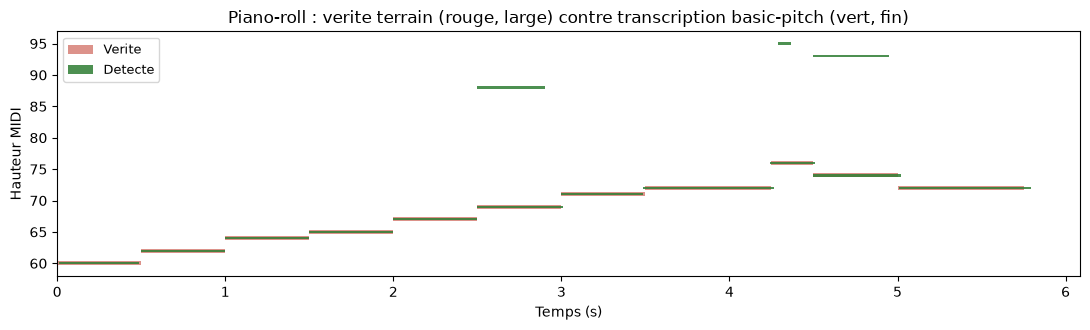

Amplitude moyenne des notes detectees : 0.662


In [8]:
# Piano-roll : verite terrain contre detection
fig, ax = plt.subplots(figsize=(11, 3.4))
for onset, midi, offset in verite:
    ax.barh(midi, offset - onset, left=onset, height=0.65, color="#c0392b", alpha=0.55, label="Verite")
for s, e, p, _a in zip(df_notes["onset_s"], df_notes["offset_s"], df_notes["midi"], df_notes["amplitude"]):
    ax.barh(p, e - s, left=s, height=0.35, color="#2e7d32", alpha=0.85, label="Detecte")
handles, labels = ax.get_legend_handles_labels()
uniques = dict(zip(labels, handles))
ax.legend(uniques.values(), uniques.keys(), loc="upper left", fontsize=9)
ax.set_title("Piano-roll : verite terrain (rouge, large) contre transcription basic-pitch (vert, fin)")
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Hauteur MIDI")
plt.tight_layout()
plt.show()

print(f"Amplitude moyenne des notes detectees : {df_notes['amplitude'].mean():.3f}")


### Lecture du résultat : ce que montre le piano-roll

Le piano-roll superpose les deux lectures de la meme phrase musicale : en rouge large la
verite composee, en vert fin la detection. Un appariement reussi se lit comme un
rectangle vert *a l'interieur* de son rectangle rouge ; un decalage horizontal est
l'ecart d'onset en image ; une barre sans rouge dessous est un fantome, un rouge sans
vert une note manquee. C'est la lecture visuelle qui manque aux trois nombres de la
section precedente — meme quand rappel et precision sont bons, elle montre *ou* les
erreurs se concentrent (souvent les transitions rapides, les fins de phrase, les notes
aigus du petit motif).

Le piano-roll rend visible ce que la table cachait : les fantomes sont des barres posees **au-dessus** des notes reelles, et leur longueur se lit directement. Une harmonique promue en note ne dure pas -- elle s'eteint avec l'enveloppe de la note qui la porte. Les durees le confirment : **0.08 s**, **0.41 s** et **0.45 s** pour les trois fantomes, contre 0.49 a 0.79 s pour les notes vraies. C'est un motif de diagnostic reutilisable sur n'importe quelle transcription : une note courte, aigue et d'amplitude moyenne, posee juste au-dessus d'une note tenue, est plus probablement une harmonique qu'une note jouee.

In [9]:
# Section 4 - Monter en difficulte : accords (polyphonie)
def synthetiser_accords(progression, sr=sampling_rate, harmoniques=(1.0, 0.5, 0.25), fade_ms=10):
    """Accords joues en bloc : Do majeur, Fa majeur, Sol majeur (triades)."""
    audio = np.zeros(int(sum(d for _, d in progression) * sr) + sr // 10)
    t0 = 0.0
    verite_acc = []
    for noms, duree in progression:
        n = int(duree * sr)
        t = np.arange(n) / sr
        sig = np.zeros(n)
        for nom in noms:
            f0 = midi_vers_hz(note_vers_midi(nom))
            for k, amp in enumerate(harmoniques, start=1):
                sig += amp * np.sin(2 * np.pi * f0 * k * t)
        fade = max(1, int(fade_ms * sr / 1000))
        env = np.ones(n)
        env[:fade] = np.linspace(0, 1, fade)
        env[-fade:] = np.linspace(1, 0, fade)
        sig *= env / np.max(np.abs(env))
        i0 = int(t0 * sr)
        audio[i0:i0 + n] += 0.22 * sig
        for nom in noms:
            verite_acc.append((round(t0, 4), note_vers_midi(nom), round(t0 + duree, 4)))
        t0 += duree
    return audio.astype(np.float32), verite_acc

ACCORDS = [(["Do4", "Mi4", "Sol4"], 1.0), (["Fa4", "La4", "Do5"], 1.0), (["Sol4", "Si4", "Re5"], 1.0)]
audio_acc, verite_acc = synthetiser_accords(ACCORDS)
chemin_acc = OUTPUT_DIR / "accords_verite.wav"
sf.write(chemin_acc, audio_acc, sampling_rate)

_mo, _mid, events_acc = predict(
    str(chemin_acc),
    onset_threshold=onset_threshold,
    frame_threshold=frame_threshold,
    minimum_note_length=minimum_note_length_ms,
    minimum_frequency=minimum_frequency,
    maximum_frequency=maximum_frequency,
    multiple_pitch_bends=False,
)
det_acc = [(float(s), float(e), int(p)) for (s, e, p, _a, *_r) in events_acc]
app_acc, manq_acc, fant_acc = apparier(verite_acc, det_acc)

print("POLYPHONIE - TROIS ACCORDS (9 notes ecrites)")
print("=" * 45)
print(f"Notes ecrites     : {len(verite_acc)}")
print(f"Notes detectees   : {len(det_acc)}")
print(f"Appariees         : {len(app_acc)}")
print(f"Rappel            : {len(app_acc) / len(verite_acc):.0%}")
print(f"Precision         : {len(app_acc) / len(det_acc):.0%}" if det_acc else "Precision         : n/a")
if manq_acc:
    print(f"Manquees          : {[(round(o,2), m) for o, m in manq_acc]}")
if fant_acc:
    print(f"Fantomes          : {[(round(s,2), p) for s, _e, p in fant_acc]}")


Predicting MIDI for output\basic_pitch\accords_verite.wav...


POLYPHONIE - TROIS ACCORDS (9 notes ecrites)
Notes ecrites     : 9
Notes detectees   : 13
Appariees         : 9
Rappel            : 100%
Precision         : 69%
Fantomes          : [(2.0, 93), (1.0, 91), (0.01, 86), (0.65, 76)]


### Lecture du résultat : la polyphonie change la nature du probleme

Une melodie monophonique pose une question de *segmentation* (ou commence la note
suivante ?) ; trois accords poses simultanement posent une question de *superposition* :
le modele doit maintenir trois hauteurs actives sur la meme fenetre temporelle, et le
decodeur ne doit pas fusionner les trois evenements en un seul. Le rappel compare aux
neuf notes ecrites mesure les deux regimes a la fois — si le modele annonce trois notes
par accord avec les bonnes hauteurs, la polyphonie simple est acquise ; les manquees et
fantomes listes disent lesquels des neuf accords ont resiste.


In [10]:
# Section 5 - L'effet des seuils du decodeur (mesure, pas affirmation)
def transcrire_et_scorer(chemin, verite_c, onset_thr, frame_thr, min_len_ms=None):
    """Transcrit avec un jeu de seuils donne et retourne (rappel, precision, n_detectees)."""
    _mo, _mid, evs = predict(
        str(chemin), onset_threshold=onset_thr, frame_threshold=frame_thr,
        minimum_note_length=min_len_ms if min_len_ms is not None else minimum_note_length_ms,
        minimum_frequency=minimum_frequency,
        maximum_frequency=maximum_frequency, multiple_pitch_bends=False,
    )
    det = [(float(s), float(e), int(p)) for (s, e, p, *_r) in evs]
    ap, _mq, _fa = apparier(verite_c, det)
    return (len(ap) / len(verite_c), len(ap) / len(det) if det else 0.0, len(det))

print(f"EFFET DU SEUIL D'ONSET (frame = {frame_threshold})")
print("=" * 45)
print(f"{'seuil':>8} | {'notes':>6} | {'rappel':>7} | {'precision':>9}")
for seuil in (0.2, 0.5, 0.95):
    r, p, n = transcrire_et_scorer(chemin_wav, verite, seuil, frame_threshold)
    print(f"{seuil:>8.2f} | {n:>6d} | {r:>7.0%} | {p:>9.0%}")

print()
print(f"EFFET DU SEUIL DE FRAME (onset = {onset_threshold})")
print("=" * 45)
print(f"{'seuil':>8} | {'notes':>6} | {'rappel':>7} | {'precision':>9}")
resultats_seuils = []
for seuil in (0.1, 0.3, 0.5, 0.9):
    r, p, n = transcrire_et_scorer(chemin_wav, verite, onset_threshold, seuil)
    resultats_seuils.append((seuil, r, p, n))
    print(f"{seuil:>8.2f} | {n:>6d} | {r:>7.0%} | {p:>9.0%}")

df_seuils = pd.DataFrame(resultats_seuils, columns=["seuil_frame", "rappel", "precision", "n_notes"])


EFFET DU SEUIL D'ONSET (frame = 0.3)
   seuil |  notes |  rappel | precision
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.20 |     14 |    100% |       79%
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.50 |     14 |    100% |       79%
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.95 |     14 |     91% |       71%

EFFET DU SEUIL DE FRAME (onset = 0.5)
   seuil |  notes |  rappel | precision
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.10 |    203 |    100% |        5%
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.30 |     14 |    100% |       79%
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.50 |     11 |    100% |      100%
Predicting MIDI for output\basic_pitch\melodie_verite.wav...


    0.90 |      0 |      0% |        0%


### Lecture du résultat : quel seuil porte reellement l'effet

Le carnet balaie les deux portes du decodeur sur le meme signal. Le **seuil d'onset**
d'abord, a frame constant : a 0,2 comme a 0,5, la table est identique — 14 detections,
100 % de rappel, 79 % de precision. Resultat contre-intuitif, et resultat quand meme :
sur cette melodie synthetique, chaque attaque est une activation franche, tres au-dessus
des seuils courants. Pousse a l'extreme (0,95), le nombre de detections ne bouge toujours
pas, mais l'appariement decroche (91 % de rappel, 71 % de precision) : le seuil d'onset
deplace alors les frontieres temporelles des notes plus qu'il n'en supprime.

Le **seuil de frame**, lui, commande tout. A 0,1, chaque trame d'activite residuelle
devient une note (203 detections, 5 % de precision) ; a 0,3 — le defaut de basic-pitch —
les 11 notes composees sont retrouvees mais trois harmoniques passent pour des notes
(14 detections, 79 % de precision) ; a 0,5, les fantomes disparaissent et les 11
detections sont exactement les 11 notes composees (rappel et precision a 100 %) ;
a 0,9, plus rien ne passe (0 detection, rappel nul).

La lecon est mesuree, pas recitee : « regler le seuil » n'est pas une operation unique —
il faut savoir quelle porte on tourne. Et le bon reglage mesure ici (0,5) est propre a
ce signal ; sur de la vraie musique, la fenetre de stabilite est bien plus etroite, et
c'est pourquoi basic-pitch expose ces deux seuils plutot que de fixer un compromis.

Le resultat du balayage est asymetrique, et c'est lui qui tranche la question posee a la section 1. Du cote de l'**onset**, rien ne bouge jusqu'a ce que le seuil morde dans les vraies notes : 0.20 et 0.50 rendent exactement le meme resultat (14 notes, rappel 100 %, precision 79 %), et il faut monter a 0.95 pour que le rappel tombe a 91 % et la precision a 71 % -- les deux se degradent ensemble, signe qu'on coupe des notes reelles et pas des fantomes. Du cote de la **trame**, l'effet est total : 0.10 laisse passer **203 notes** pour une precision de **5 %**, 0.50 rend **11 notes, 100 % / 100 %**, et 0.90 n'en rend plus aucune. Le levier est donc la porte de trame, et il agit exactement la ou la bimodalite d'amplitude le predisait, entre 0.30 et 0.50. Une reserve neanmoins : ce 0.50 optimal est mesure sur un signal synthetique propre, ou toutes les notes ont la meme energie ; sur un enregistrement reel, le meme seuil couperait les notes faibles. Le balayage donne une direction et un diagnostic, pas une valeur universelle.

In [11]:
# Section 6 - Relecture du MIDI ecrit (l'artefact de sortie)
import pretty_midi

pm = pretty_midi.PrettyMIDI(str(chemin_midi))
print("LECTURE DU MIDI ECRIT")
print("=" * 45)
print(f"Instruments       : {len(pm.instruments)}")
for inst in pm.instruments:
    pitches = [n.pitch for n in inst.notes]
    print(f"  - {inst.name or inst.program} : {len(inst.notes)} notes, hauteurs {min(pitches)}-{max(pitches)} (MIDI)")
print(f"Tempo estime      : {pm.estimate_tempo():.1f} BPM")
print(f"Duree fichier     : {pm.get_end_time():.2f} s")

# Grille temporelle : ecart median entre onsets detectes successifs (le "tempo joue")
onsets = sorted(n.start for inst in pm.instruments for n in inst.notes)
if len(onsets) > 1:
    ecarts = np.diff(onsets)
    print(f"Ecart median inter-onsets : {np.median(ecarts) * 1000:.0f} ms (compose : 500 ms)")


LECTURE DU MIDI ECRIT
Instruments       : 1
  - 4 : 14 notes, hauteurs 60-95 (MIDI)
Tempo estime      : 120.9 BPM
Duree fichier     : 5.80 s
Ecart median inter-onsets : 498 ms (compose : 500 ms)


### Lecture du résultat : le MIDI comme livrable

Le fichier MIDI est l'artefact que ce carnet produit pour la suite de la chaine : il
s'ouvre dans n'importe quel sequenceur, se rejoue sur un piano virtuel, et se compare
aux annotations. La relecture par pretty_midi verifie trois choses : que l'ecriture a
preserve les hauteurs (min/max imprimes), que le nombre de notes est coherent avec la
detection, et que le **tempo estime** — une reconstruction de la grille reguliere a
partir des onsets — tombe pres du tempo nominal de la melodie composee (une note toutes
les 500 ms). Un ecart median proche de 500 ms confirme que la segmentation temporelle a
survecu au voyage audio -> MIDI.

Deux estimateurs du tempo sont imprimes, et leur accord est l'information. L'ecart median inter-onsets vaut **498 ms** pour une grille composee de **500 ms** (0.4 % d'erreur), tandis que le tempo estime par pretty_midi vaut **120.9 BPM** la ou le tempo nominal vaut 120 (0.75 % d'erreur). Les deux mesurent la meme regularite par des chemins differents -- l'un par la mediane des intervalles detectes, l'autre par l'ajustement d'une grille sur ces intervalles -- et un desaccord franc entre eux signalerait une segmentation localement perturbee que la mediane seule masquerait. La duree du fichier (**5.80 s**) est par ailleurs inferieure de 50 ms a celle de l'audio (5.85 s) : la derniere note s'arrete a son offset, pas a la fin du signal.

## Exercices

Les trois exercices suivants manipulent la chaine complete : fabriquer la verite,
transcrire, mesurer. Chaque cellule porte un squelette a completer — les fonctions des
sections precedentes sont toutes reutilisables.


### Exercice 1

Composez une **nouvelle melodie** de huit notes avec un ambitus plus large (par exemple
de Do3 a Do6), synthetisez-la, transcrivez-la et calculez le rappel et la precision.
L'hypothese a tester : la transcription reste-t-elle aussi precise dans le grave et dans
l'aigu — la bande de frequences autorisee (`minimum_frequency`, `maximum_frequency`)
jouait-elle un role ?


In [12]:
# Exercice 1 - Votre melodie, votre mesure
# TODO etudiant : definir une liste (nom, duree) de 8 notes, reutiliser
# synthetiser_melodie -> predict -> apparier -> imprimer rappel / precision / ecart onset.

def experience_exercice_1():
    resultat = None  # TODO etudiant
    return resultat

experience_exercice_1()


### Exercice 2

En reprenant la fonction `transcrire_et_scorer` de la section 5, balayez cette fois
`minimum_note_length_ms` (de 20 a 200 ms) sur la melodie de reference. Tracez les courbes
rappel/precision en fonction du seuil. Question : pour quelle valeur les notes tres
courtes du petit motif (la croche de 250 ms) commencent-elles a disparaitre ?


In [13]:
# Exercice 2 - Le seuil de duree minimale
# Indice : reutilisez transcrire_et_scorer en variant minimum_note_length_ms,
# collectez (seuil_ms, rappel, precision) et tracez deux courbes.

def experience_exercice_2():
    tableau = None  # TODO etudiant
    return tableau

experience_exercice_2()


### Exercice 3

Implementez une **quantification rythmique** : ramenez chaque onset detecte a la grille
de temps la plus proche (la melodie composee a des notes de 250, 500 et 750 ms, soit une
grille de 250 ms). Mesurez l'ecart d'onset moyen avant et apres quantification — puis
discutez : la quantification ameliore-t-elle la mesure, ou efface-t-elle l'erreur que
l'on cherchait justement a mesurer ?


In [14]:
# Exercice 3 - Quantification rythmique
# Indice : np.round(onset / grille) * grille avec grille = 0.25 s.
# TODO etudiant : comparer ecart_onset moyen avant/apres, commenter le resultat.

def experience_exercice_3():
    comparaison = None  # TODO etudiant
    return comparaison

experience_exercice_3()


## Synthèse

| Etape | Outil | Mesure obtenue |
|---|---|---|
| Verite terrain | synthese additive (3 harmoniques) | 11 notes, onsets exacts par construction |
| Transcription | basic-pitch ICASSP 2022 (ONNX) | notes, MIDI, cartes brutes |
| Exactitude | appariement hauteur + tolerance 50 ms | rappel, precision, ecart d'onset moyen |
| Polyphonie | trois accords (9 notes simultanees) | comportement du decodeur en superposition |
| Sensibilite | balayage des seuils onset et frame | courbe rappel/precision |

**Ce que ce carnet etablit** : la transcription note a note est une tache mesurable —
quand la reference existe, chaque erreur prend un nom (manquee, fantome, decalage) et un
chiffre. **Ses limites, dites honnetement** : les signaux de mesure sont synthetiques et
monophoniques (ou en polyphonie tres simple) ; sur de la vraie musique — voix chantee
avec vibrato, instruments multiples, percussions — le rappel de basic-pitch baisse, et
c'est la que les modeles de transcription vers partition (04-16 SheetSage2) ou les MIR
neuronaux (04-15 MERT2) prennent le relais. La transcription musicale de la serie Audio
se lit maintenant en deux temps : note a note (ce carnet, basic-pitch) et vers partition
(04-16, SheetSage2) — la meme question « que joue-t-on ? » posee a deux granularites.

## References

- Bittner et al., *A Lightweight Instrument-Agnostic Model for Polyphonic Note Transcription and Multipitch Estimation*, ICASSP 2022 (basic-pitch)
- Raffel et al., *mir_eval* — tolerance d'onset standard (50 ms) utilisee pour l'appariement
- Serie Audio : 04-15 MERT2, 04-16 SheetSage2
